# 06. Figures

Four charts for the README and the dashboard.

**Output:** `outputs/figures/*.png`

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src import config as C

plt.rcParams.update(C.PLOT_STYLE)

dec      = pd.read_csv(C.PROCESSED / "decomposition.csv")
per_cap  = pd.read_csv(C.PROCESSED / "nigeria_per_capita.csv")
gap      = pd.read_csv(C.PROCESSED / "yield_gap.csv")
fert     = pd.read_csv(C.PROCESSED / "fertilizer.csv")
headline = json.load(open(C.PROCESSED / "headline.json"))

## 1. Where the growth came from

Two bars per crop. Horizontal because the labels are words, and with a zero line because
the point is that the bars often go opposite ways.

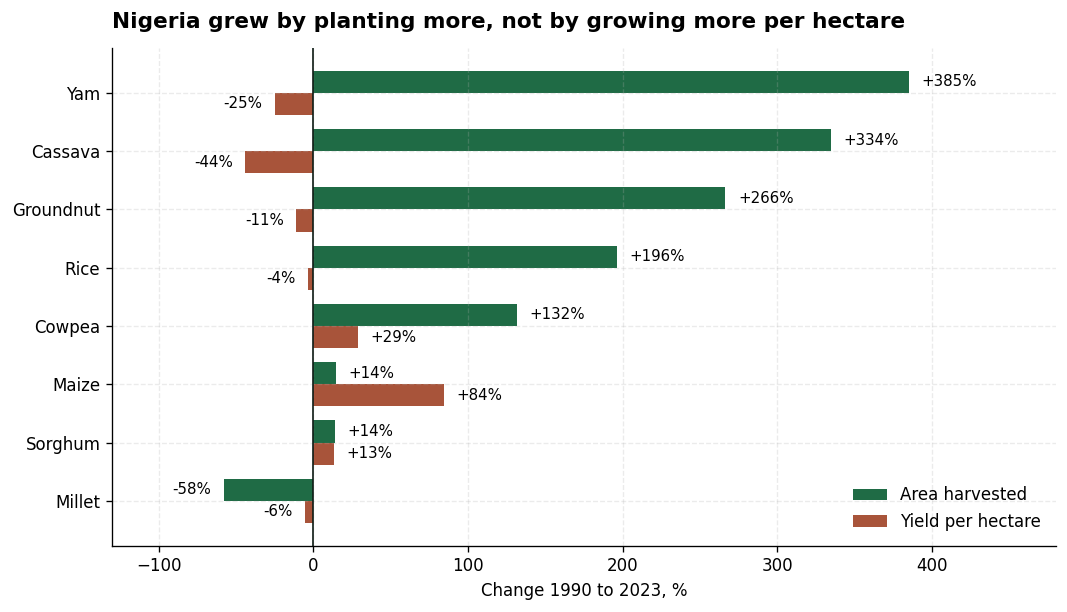

In [2]:
d = dec.sort_values("area_growth_pct")

fig, ax = plt.subplots(figsize=(9, 5.2))
y, h = np.arange(len(d)), 0.38

ax.barh(y + h / 2, d["area_growth_pct"],  h, color=C.GREEN, label="Area harvested")
ax.barh(y - h / 2, d["yield_growth_pct"], h, color=C.CLAY,  label="Yield per hectare")
ax.axvline(0, color=C.INK, lw=1)

for i, (a, b) in enumerate(zip(d["area_growth_pct"], d["yield_growth_pct"])):
    ax.text(a + (8 if a >= 0 else -8), i + h / 2, f"{a:+.0f}%",
            va="center", ha="left" if a >= 0 else "right", fontsize=9)
    ax.text(b + (8 if b >= 0 else -8), i - h / 2, f"{b:+.0f}%",
            va="center", ha="left" if b >= 0 else "right", fontsize=9)

ax.set_yticks(y); ax.set_yticklabels(d["crop"])
ax.set_xlabel(f"Change {C.START_YEAR} to {C.END_YEAR}, %")
ax.set_title("Nigeria grew by planting more, not by growing more per hectare", loc="left")
ax.set_xlim(-130, 480)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(C.FIGURES / "01_decomposition.png", bbox_inches="tight")
plt.show()

## 2. Food per person

A line, because it is one thing over time. The peak is labelled because that is the
point.

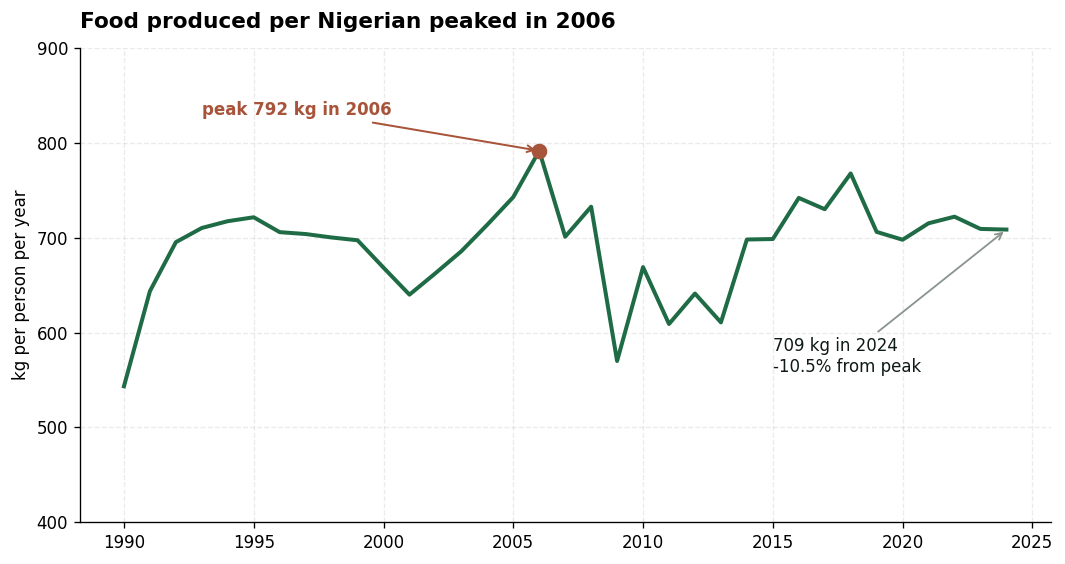

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(per_cap["year"], per_cap["kg_per_person"], color=C.GREEN, lw=2.4)

peak = per_cap.loc[per_cap["kg_per_person"].idxmax()]
last = per_cap.iloc[-1]

ax.scatter([peak["year"]], [peak["kg_per_person"]], s=70, color=C.CLAY, zorder=5)
ax.annotate(f"peak {peak['kg_per_person']:.0f} kg in {int(peak['year'])}",
            xy=(peak["year"], peak["kg_per_person"]),
            xytext=(peak["year"] - 13, peak["kg_per_person"] + 38),
            fontsize=10, color=C.CLAY, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color=C.CLAY, lw=1.2))

ax.annotate(f"{last['kg_per_person']:.0f} kg in {int(last['year'])}\n"
            f"{(last['kg_per_person'] / peak['kg_per_person'] - 1) * 100:+.1f}% from peak",
            xy=(last["year"], last["kg_per_person"]),
            xytext=(last["year"] - 9, last["kg_per_person"] - 150),
            fontsize=10, color=C.INK,
            arrowprops=dict(arrowstyle="->", color=C.GREY, lw=1.1))

ax.set_ylabel("kg per person per year")
ax.set_title(f"Food produced per Nigerian peaked in {int(peak['year'])}", loc="left")
ax.set_ylim(400, 900)

fig.tight_layout()
fig.savefig(C.FIGURES / "02_per_capita.png", bbox_inches="tight")
plt.show()

The axis starts at 400 rather than zero. On a line showing change that is fine, but
it is a choice.

The line is bumpy, which is why I say output per person stopped improving rather than
collapsed.

## 3. The yield gap

Three numbers per crop would need 24 bars. Dots on a line do it in 8 rows, and the line
itself shows the size of the gap.

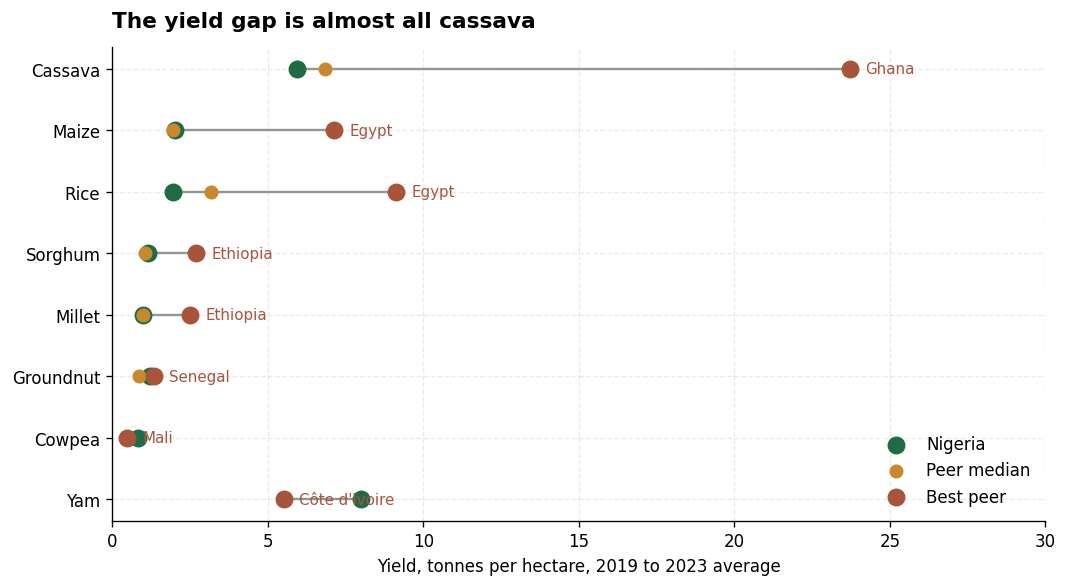

In [4]:
g = gap.sort_values("upside_t")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(g))

for i, r in enumerate(g.itertuples()):
    ax.plot([min(r.nigeria_t_ha, r.best_t_ha), max(r.nigeria_t_ha, r.best_t_ha)],
            [i, i], color=C.GREY, lw=1.4, zorder=1)

ax.scatter(g["nigeria_t_ha"],     y, s=95, color=C.GREEN, zorder=3, label="Nigeria")
ax.scatter(g["peer_median_t_ha"], y, s=55, color=C.GOLD,  zorder=3, label="Peer median")
ax.scatter(g["best_t_ha"],        y, s=95, color=C.CLAY,  zorder=3, label="Best peer")

for i, r in enumerate(g.itertuples()):
    ax.text(r.best_t_ha + 0.5, i, r.best_country, va="center", fontsize=9, color=C.CLAY)

ax.set_yticks(y); ax.set_yticklabels(g["crop"])
ax.set_xlabel(f"Yield, tonnes per hectare, {C.REF_WINDOW[0]} to {C.REF_WINDOW[1]} average")
ax.set_title("The yield gap is almost all cassava", loc="left")
ax.set_xlim(0, 30)
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig(C.FIGURES / "03_yield_gap.png", bbox_inches="tight")
plt.show()

Cassava's line runs across the whole chart. Everything else is bunched on the left.

On yam and cowpea the Nigeria dot is to the right of the best peer, so Nigeria is
ahead.

## 4. Fertilizer

Log scale, because Egypt uses about a thousand times what Niger does and a normal axis
would squash everything else flat.

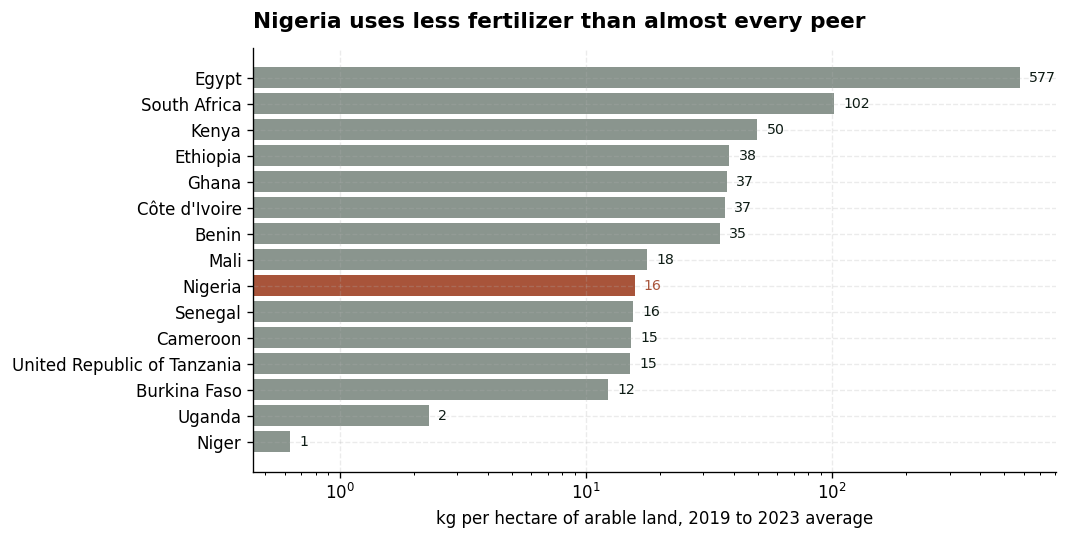

In [5]:
f = fert.sort_values("fert_kg_ha")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(f["country"], f["fert_kg_ha"],
        color=[C.CLAY if c == "Nigeria" else C.GREY for c in f["country"]])

ax.set_xscale("log")
ax.set_xlabel(f"kg per hectare of arable land, {C.REF_WINDOW[0]} to {C.REF_WINDOW[1]} average")
ax.set_title("Nigeria uses less fertilizer than almost every peer", loc="left")

for i, (c, v) in enumerate(zip(f["country"], f["fert_kg_ha"])):
    ax.text(v * 1.09, i, f"{v:,.0f}", va="center", fontsize=8.5,
            color=C.CLAY if c == "Nigeria" else C.INK)

fig.tight_layout()
fig.savefig(C.FIGURES / "04_fertilizer.png", bbox_inches="tight")
plt.show()

In [6]:
for p in sorted(C.FIGURES.glob("*.png")):
    print(f"{p.name:<26} {p.stat().st_size / 1024:5.0f} KB")

01_decomposition.png          87 KB
02_per_capita.png             96 KB
03_yield_gap.png              86 KB
04_fertilizer.png             86 KB
